# Evaluación del modelo (Fase 2)

¿El LSTM predice los Mundiales mejor que reglas simples? Este notebook **no entrena ni copia código**: importa las funciones de `web/fases/` y lee lo que dejó `python manage.py evaluar_modelos`.

**Partición temporal (nada del futuro):**
- *Selección de configuración*: entrena con los ciclos hasta 2010 (eliminatorias y Mundiales) y valida con el ciclo 2014 completo.
- *Prueba*: reentrena hasta 2014 y mide **una sola vez** en los 128 partidos de los Mundiales 2018 y 2022.

**Métricas:** MAE de goles, % de resultado acertado (local / empate / visitante), % de marcador exacto y *deviance* de Poisson (menor es mejor).

In [1]:
import json, os, sys
from pathlib import Path

RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(RAIZ / "web"))
os.environ.setdefault("DJANGO_SETTINGS_MODULE", "mundial.settings")
os.environ.setdefault("TF_CPP_MIN_LOG_LEVEL", "3")
import django
django.setup()

import pandas as pd
import matplotlib.pyplot as plt
from fases.dataset import construir_secuencias
from fases.evaluacion import evaluar, particion
from fases.predictores import cargar_predictor

resultados = json.loads((RAIZ / "experimentos" / "resultados_baseline.json").read_text(encoding="utf-8"))
print(resultados["fecha"], "-", resultados["partidos"], "partidos en", resultados["dataset"])

2026-10-19 - 8828 partidos en partidos_features.csv


## 1. Selección: largo de la secuencia (K) y bloques de la entrada

Media ± desviación de 3 semillas en la validación (ciclo 2014, 868 partidos).

In [2]:
filas = []
for s in resultados["seleccion"]:
    v = s["validacion"]
    filas.append({"K": s["k"], "rival": s["con_rival"], "contexto": s["con_contexto"],
                  "deviance": f'{v["deviance"]["media"]:.4f} ± {v["deviance"]["desv"]:.4f}',
                  "acierto %": f'{v["acierto_resultado"]["media"]:.1f} ± {v["acierto_resultado"]["desv"]:.1f}',
                  "épocas": s["epocas"]})
pd.DataFrame(filas)

,K,rival,contexto,deviance,acierto %,épocas
0,1,True,True,0.7409 ± 0.0025,59.6 ± 0.5,"[11, 11, 12]"
1,3,True,True,0.7447 ± 0.0022,59.6 ± 0.5,"[8, 7, 7]"
2,5,True,True,0.7475 ± 0.0016,59.9 ± 0.2,"[7, 6, 7]"
3,8,True,True,0.7450 ± 0.0030,60.7 ± 0.2,"[6, 7, 7]"
4,12,True,True,0.7413 ± 0.0031,60.5 ± 0.4,"[5, 6, 5]"
5,1,False,True,0.7415 ± 0.0020,59.9 ± 0.2,"[13, 13, 12]"
6,1,True,False,0.7604 ± 0.0003,58.1 ± 0.2,"[12, 7, 7]"
7,1,False,False,0.7629 ± 0.0007,58.0 ± 0.3,"[15, 11, 8]"


In [3]:
elegida = resultados["elegida"]
print("Configuración elegida:", elegida)

Configuración elegida: {'k': 1, 'con_rival': False, 'con_contexto': True, 'epocas': 13}


## 2. Prueba: Mundiales 2018 y 2022 contra las líneas base

In [4]:
nombres = {"medias": "(b) Poisson con medias", "mas_puntos": "(a) gana el de más puntos", "empate": "(c) siempre 1-1", "lstm": "LSTM"}
tabla = []
for clave, r in resultados["prueba"].items():
    valor = (lambda m: r[m]["media"]) if clave == "lstm" else (lambda m: r[m])
    tabla.append({"modelo": nombres[clave], "acierto resultado %": round(valor("acierto_resultado"), 1),
                  "marcador exacto %": round(valor("marcador_exacto"), 1), "MAE goles": round(valor("mae_goles"), 3),
                  "deviance": round(valor("deviance"), 3)})
tabla = pd.DataFrame(tabla).set_index("modelo")
tabla

,acierto resultado %,marcador exacto %,MAE goles,deviance
modelo,,,,
(b) Poisson con medias,43.0,9.4,0.984,0.957
(a) gana el de más puntos,46.1,8.6,1.094,11.683
(c) siempre 1-1,21.9,9.4,0.902,1.000
LSTM,53.4,10.2,0.931,0.935


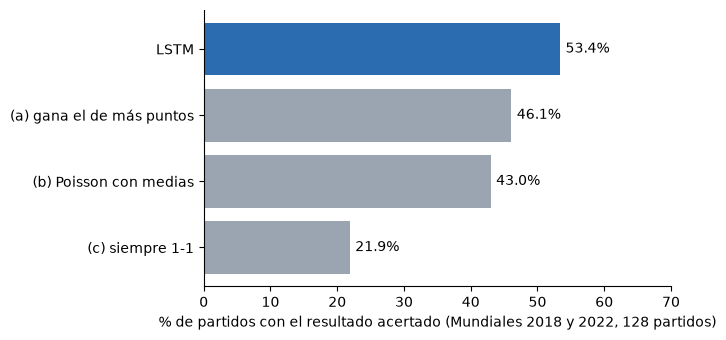

In [5]:
fig, ax = plt.subplots(figsize=(7, 3.5))
datos = tabla["acierto resultado %"].sort_values()
ax.barh(datos.index, datos.values, color=["#9aa5b1" if m != "LSTM" else "#2b6cb0" for m in datos.index])
for y, x in enumerate(datos.values):
    ax.text(x + 0.8, y, f"{x:.1f}%", va="center")
ax.set_xlabel("% de partidos con el resultado acertado (Mundiales 2018 y 2022, 128 partidos)")
ax.set_xlim(0, 70)
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

## 3. Comprobación: el modelo guardado da lo mismo

Se carga `data/modelos/lstm-<fecha>/` con `cargar_predictor` y se evalúa de nuevo con `evaluar`, las mismas funciones que usa el comando.

In [6]:
ds = pd.read_csv(RAIZ / "data" / "datasets" / "partidos_features.csv")
predictor, esquema = cargar_predictor(RAIZ / "data" / "modelos" / resultados["modelo"])
c = esquema["config"]
sec = construir_secuencias(ds, k=c["k"], con_rival=c["con_rival"], con_contexto=c["con_contexto"])
_, _, prueba = particion(ds, hasta=2014, prueba=[2018, 2022])
evaluar(predictor, ds, sec, prueba)

{'partidos': 128,
 'mae_goles': 0.9398329155519605,
 'acierto_resultado': 53.125,
 'marcador_exacto': 8.59375,
 'deviance': 0.9265353027370928}

## 4. Lectura

- **Frase para el README:** el LSTM acierta el resultado en ~53 % de los partidos de 2018–2022, frente a 46 % de la mejor línea base.
- **Cuidado con el tamaño de la prueba:** 128 partidos dan un margen de ±9 puntos (intervalo del 95 %). La ventaja es real en validación (868 partidos: ~60 % frente a ~49–51 %), pero en prueba hay que leerla como "probablemente mejor", no como definitiva.
- **K = 1:** ver más partidos pasados no mejora; cada paso ya trae las métricas *acumuladas* del ciclo, así que el último paso resume la historia.
- **El contexto sí aporta** (local / neutral, tipo de partido): quitarlo empeora la deviance de ~0,740 a ~0,760. **Las métricas del rival en el mismo paso no aportan**: el modelo ya ve la historia del rival por su propia rama.
- **MAE:** "siempre 1-1" tiene menor MAE porque 1 gol es casi la mediana; por eso el MAE solo no sirve para elegir modelo.
- **Marcador exacto (~9 %)**: igual para todos; predecir el marcador exacto en fútbol es casi azar.